# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

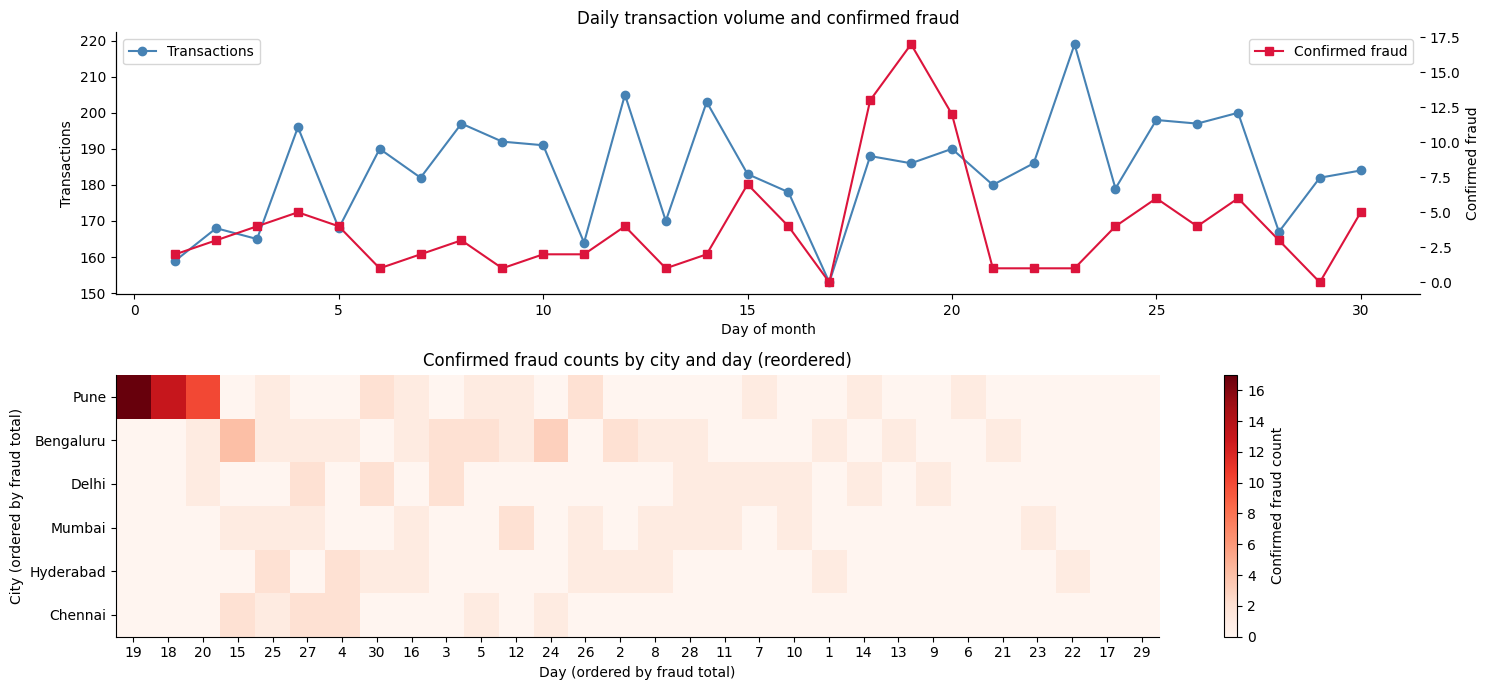

Top city-day cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  2       2
           5       2
Pune       30      2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1: daily transaction volume and confirmed fraud on a second axis
daily = tx.groupby("day").agg(transaction_count=("txn_id", "count"),
                               confirmed_fraud=("is_fraud", "sum"))
ax1 = axes[0]
ax1.plot(daily.index, daily["transaction_count"], marker="o", color="steelblue",
         label="Transactions")
ax1.set_ylabel("Transactions")
ax1.set_xlabel("Day of month")
ax1.set_title("Daily transaction volume and confirmed fraud")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily["confirmed_fraud"], marker="s", color="crimson",
         label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud")
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

# TODO 2: city × day fraud-count matrix, reordered by row and column totals
heat = tx.pivot_table(index="city", columns="day", values="is_fraud",
                      aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds", interpolation="nearest")
axes[1].set_title("Confirmed fraud counts by city and day (reordered)")
axes[1].set_xlabel("Day (ordered by fraud total)")
axes[1].set_ylabel("City (ordered by fraud total)")
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
fig.colorbar(im, ax=axes[1], label="Confirmed fraud count")

plt.tight_layout(); plt.show()

# TODO 3: print the city-day cells with the most confirmed fraud
top_cells = heat.stack().sort_values(ascending=False).head(10)
print("Top city-day cells by confirmed fraud:")
print(top_cells.to_string())


**Reflection:** The overview shows a pronounced cluster in **Pune on days 18–20**: those three city-day cells contain 40 confirmed fraud cases (13, 17 and 10), far more than any other city-day cell. A detector-score-sorted alert list would rank individual transactions but hide this temporal and geographic concentration. The lecture concept is **reordered matrix / overview first**: sorting rows and columns by their totals makes the pattern visually prominent.

_Your answer:_

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

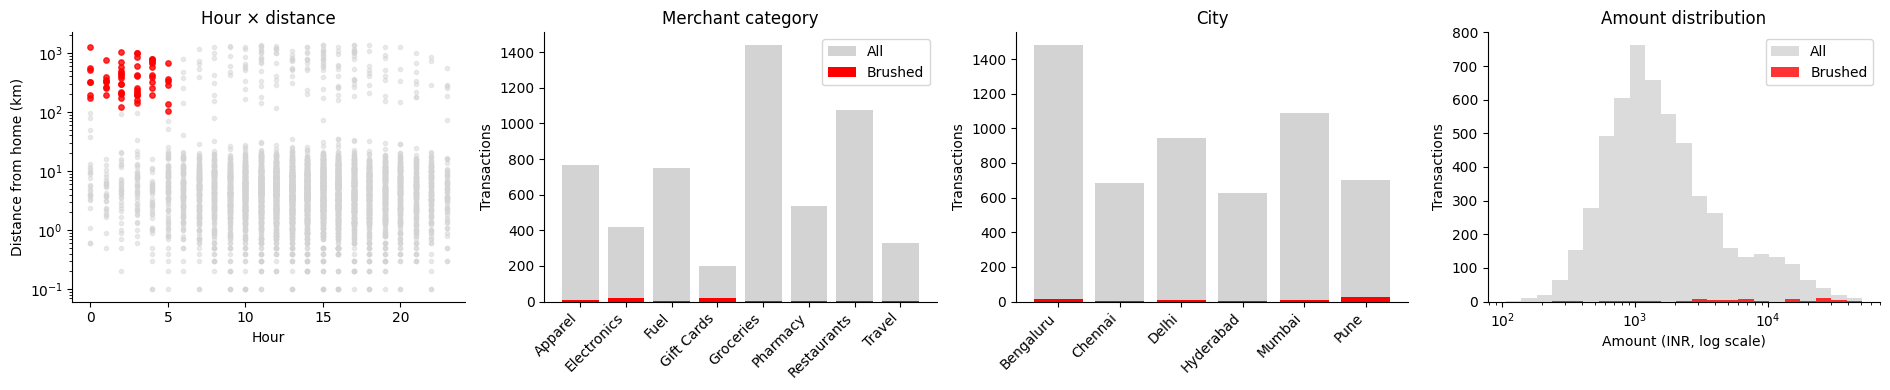

Brushed transactions: 61
Fraud rate inside brush: 86.9%
Overall fraud rate: 2.2%
Share of all confirmed fraud captured: 44.2%


In [3]:
# TODO 1: define the night-time, far-from-home brush
brush = (tx["night"] & (tx["distance_from_home_km"] > 100))

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2: coordinated views; brushed observations are red, all others grey
unselected = ~brush
axes[0].scatter(tx.loc[unselected, "hour"], tx.loc[unselected, "distance_from_home_km"],
                c="lightgrey", s=9, alpha=.45)
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"],
                c="red", s=15, alpha=.8)
axes[0].set_yscale("log")
axes[0].set(xlabel="Hour", ylabel="Distance from home (km)", title="Hour × distance")

cat_total = tx["merchant_category"].value_counts().sort_index()
cat_brush = tx.loc[brush, "merchant_category"].value_counts().reindex(cat_total.index, fill_value=0)
x = np.arange(len(cat_total))
axes[1].bar(x, cat_total.values, color="lightgrey", label="All")
axes[1].bar(x, cat_brush.values, color="red", label="Brushed")
axes[1].set_xticks(x); axes[1].set_xticklabels(cat_total.index, rotation=45, ha="right")
axes[1].set(title="Merchant category", ylabel="Transactions")
axes[1].legend()

city_total = tx["city"].value_counts().sort_index()
city_brush = tx.loc[brush, "city"].value_counts().reindex(city_total.index, fill_value=0)
x = np.arange(len(city_total))
axes[2].bar(x, city_total.values, color="lightgrey")
axes[2].bar(x, city_brush.values, color="red")
axes[2].set_xticks(x); axes[2].set_xticklabels(city_total.index, rotation=45, ha="right")
axes[2].set(title="City", ylabel="Transactions")

bins = np.logspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 24)
axes[3].hist(tx.loc[unselected, "amount_inr"], bins=bins, color="lightgrey", alpha=.8, label="All")
axes[3].hist(tx.loc[brush, "amount_inr"], bins=bins, color="red", alpha=.8, label="Brushed")
axes[3].set_xscale("log")
axes[3].set(title="Amount distribution", xlabel="Amount (INR, log scale)", ylabel="Transactions")
axes[3].legend()

plt.tight_layout(); plt.show()

# TODO 3: brush size, fraud rates and share of all fraud captured
n_brushed = int(brush.sum())
fraud_in_brush = int(tx.loc[brush, "is_fraud"].sum())
brush_rate = tx.loc[brush, "is_fraud"].mean()
overall_rate = tx["is_fraud"].mean()
fraud_capture = fraud_in_brush / tx["is_fraud"].sum()
print(f"Brushed transactions: {n_brushed}")
print(f"Fraud rate inside brush: {brush_rate:.1%}")
print(f"Overall fraud rate: {overall_rate:.1%}")
print(f"Share of all confirmed fraud captured: {fraud_capture:.1%}")


**Reflection:** The brush contains **61 transactions**, with an **86.9% fraud rate** compared with **2.2% overall**, but it captures only **44.2% of all confirmed fraud** (53 of 120 cases). This is a useful high-precision investigation rule, but relying on it alone would miss 67 fraud cases. The linked **city and merchant-category views** show where the brushed cases are concentrated, while the other views make clear that fraud also exists outside the night-time, far-from-home segment.

_Your answer:_

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: benchmark the requested filter; use the best of five runs
filter_times = []
for _ in range(5):
    start = time.perf_counter()
    mask = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
    _ = big.loc[mask]
    filter_times.append(time.perf_counter() - start)
best_s = min(filter_times)

# TODO 2: per-item cost and maximum rows within a 0.1-second budget
per_item_us = (best_s / len(big)) * 1_000_000
max_rows = 0.1 / (per_item_us / 1_000_000)

# TODO 3: estimate 50M response time and required reduction
t_50m = per_item_us * 50_000_000 / 1_000_000
skip_pct = max(0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 7.5 ms -> 0.0075 us/row -> max 13,350,520 rows in 0.1 s
50M rows -> 0.37 s; must skip 73.3% of rows to stay under 0.1 s


**Reflection:** Besides indexing, use **aggregation / pre-aggregation** (a reduce technique): maintain counts or summaries in time, city or score buckets and let the slider query those smaller summaries. This can keep interaction responsive, but the analyst loses transaction-level detail and may miss rare cases hidden inside a bucket; the detailed records should remain available for drill-down.

_Your answer:_

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

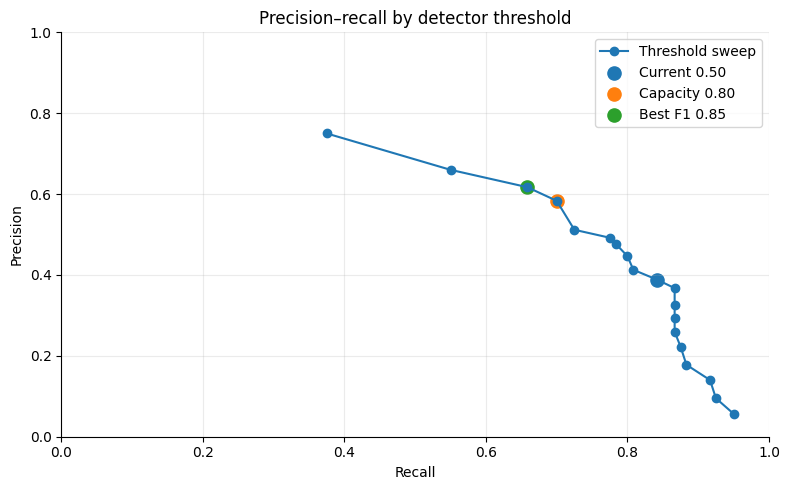

Recommend threshold 0.80: 144 alerts, precision 58.3%, recall 70.0%; this is the highest recall within capacity.
Best-F1 threshold: 0.85 (F1 0.637, 128 alerts).


In [5]:
rows = []
# TODO 1: compute confusion-matrix metrics for thresholds 0.05 to 0.95
for threshold in np.arange(0.05, 1.00, 0.05):
    predicted = tx["detector_score"] >= threshold
    actual = tx["is_fraud"].eq(1)
    tp = int((predicted & actual).sum())
    fp = int((predicted & ~actual).sum())
    fn = int((~predicted & actual).sum())
    alerts = int(predicted.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if precision + recall else 0.0)
    rows.append({"threshold": round(float(threshold), 2), "alerts": alerts,
                 "tp": tp, "fp": fp, "fn": fn, "precision": precision,
                 "recall": recall, "f1": f1})

pr = pd.DataFrame(rows)

# TODO 2: highest recall under the 150-alert capacity; best F1 overall
capacity_choice = (pr[pr["alerts"] <= 150]
                   .sort_values(["recall", "precision", "threshold"],
                                ascending=[False, False, True]).iloc[0])
best_f1 = pr.sort_values(["f1", "recall"], ascending=[False, False]).iloc[0]

# TODO 3: precision–recall curve and marked operating points
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o", label="Threshold sweep")
for _, point in pr[pr["threshold"].isin([0.50, capacity_choice["threshold"],
                                          best_f1["threshold"]])].iterrows():
    if point["threshold"] == 0.50:
        label = "Current 0.50"
    elif point["threshold"] == capacity_choice["threshold"]:
        label = f"Capacity {point['threshold']:.2f}"
    else:
        label = f"Best F1 {point['threshold']:.2f}"
    ax.scatter(point["recall"], point["precision"], s=90, label=label)
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–recall by detector threshold")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.grid(alpha=.25); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4: one-line recommendation
print(f"Recommend threshold {capacity_choice['threshold']:.2f}: "
      f"{int(capacity_choice['alerts'])} alerts, "
      f"precision {capacity_choice['precision']:.1%}, "
      f"recall {capacity_choice['recall']:.1%}; this is the highest recall within capacity.")
print(f"Best-F1 threshold: {best_f1['threshold']:.2f} "
      f"(F1 {best_f1['f1']:.3f}, {int(best_f1['alerts'])} alerts).")


**Reflection:** The **Head of Fraud Ops** should make the call, with the model providing evidence rather than deciding policy. The model's best-F1 threshold (0.85) is not automatically operationally appropriate; the team has a hard capacity of 150 alerts, so the capacity-constrained threshold (0.80) is the better starting point. Visual analytics keeps a human in the loop because the threshold trades missed fraud against investigator workload, and operational context, risk tolerance and available staffing cannot be decided by a score alone.

_Your answer:_

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: interactive investigator scatter for transactions scoring at least 0.3
flagged = tx.loc[tx["detector_score"] >= 0.3].copy()

# TODO 2: hover details and city → merchant-category drill-down
fig_scatter = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label",
    log_y=True,
    hover_data=["txn_id", "customer_id", "city", "merchant_category",
                "distance_from_home_km", "detector_score"],
    title="Flagged transactions (detector score ≥ 0.30)"
)
fig_scatter.update_layout(xaxis_title="Timestamp", yaxis_title="Amount (INR, log scale)", dragmode="select")
fig_scatter.show()

sun = (tx.groupby(["city", "merchant_category"], as_index=False)
       .agg(transaction_count=("txn_id", "count"),
            fraud_rate=("is_fraud", "mean")))
fig_sunburst = px.sunburst(
    sun, path=["city", "merchant_category"], values="transaction_count",
    color="fraud_rate", color_continuous_scale="Reds",
    hover_data={"transaction_count": True, "fraud_rate": ":.1%"},
    title="Transaction drill-down: city → merchant category (colour = fraud rate)"
)
fig_sunburst.show()


**Reflection:** Tooltips show details for only the point the investigator happens to hover over; inspecting 400 flagged cases one by one would be slow and would not reveal overall concentrations or outliers. The **overview heatmap / coordinated linked views** from this notebook fixes that by summarising the distribution first, while the scatter and sunburst then provide details-on-demand and drill-down for selected cases.

_Your answer:_

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: confirmed fraud is unusually concentrated in Pune on days 18–20.
Inside window: 107 transactions, 40 fraud, rate 37.4%
Outside window: 5413 transactions, 80 fraud, rate 1.5%
Chi-square=619.29, p-value=1.065e-136


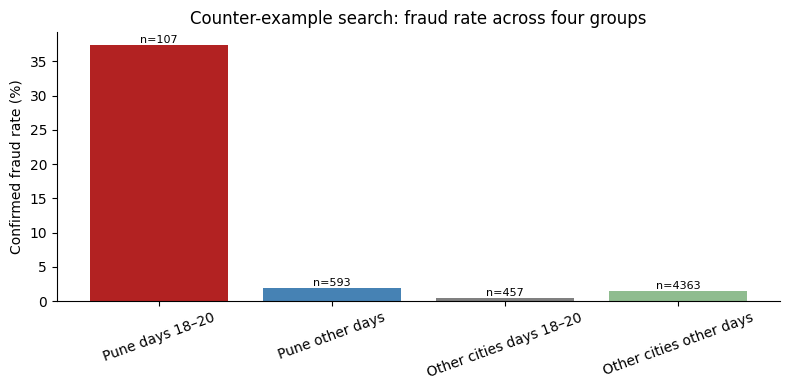

                  group  transactions fraud_rate  fraud_count
        Pune days 18–20           107     37.38%           40
        Pune other days           593      1.85%           11
Other cities days 18–20           457      0.44%            2
Other cities other days          4363      1.54%           67
Verdict: The data strongly supports a localized Pune fraud spike on days 18–20, but transaction geography and timing alone do not prove a coordinated fraud ring. Escalate the cluster for investigation and test shared customers, devices, cards and merchants.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis: the Pune fraud spike spans days 18–20
in_window = tx["city"].eq("Pune") & tx["day"].between(18, 20)

# TODO 2: fraud rates inside/outside and chi-square test
window_rate = tx.loc[in_window, "is_fraud"].mean()
outside_rate = tx.loc[~in_window, "is_fraud"].mean()
contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency)
print("Hypothesis: confirmed fraud is unusually concentrated in Pune on days 18–20.")
print(f"Inside window: {int(in_window.sum())} transactions, "
      f"{int(tx.loc[in_window, 'is_fraud'].sum())} fraud, rate {window_rate:.1%}")
print(f"Outside window: {int((~in_window).sum())} transactions, "
      f"{int(tx.loc[~in_window, 'is_fraud'].sum())} fraud, rate {outside_rate:.1%}")
print(f"Chi-square={chi2:.2f}, p-value={p_value:.3e}")

# TODO 3: counter-example searches
same_city_other_days = tx["city"].eq("Pune") & ~tx["day"].between(18, 20)
other_cities_same_days = ~tx["city"].eq("Pune") & tx["day"].between(18, 20)
rest = ~tx["city"].eq("Pune") & ~tx["day"].between(18, 20)

# TODO 4: compare all four groups visually
group_masks = {
    "Pune days 18–20": in_window,
    "Pune other days": same_city_other_days,
    "Other cities days 18–20": other_cities_same_days,
    "Other cities other days": rest,
}
group_summary = pd.DataFrame([
    {"group": name, "transactions": int(mask.sum()),
     "fraud_rate": tx.loc[mask, "is_fraud"].mean(),
     "fraud_count": int(tx.loc[mask, "is_fraud"].sum())}
    for name, mask in group_masks.items()
])
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(group_summary["group"], group_summary["fraud_rate"] * 100,
              color=["firebrick", "steelblue", "grey", "darkseagreen"])
ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Counter-example search: fraud rate across four groups")
ax.tick_params(axis="x", rotation=20)
for bar, n in zip(bars, group_summary["transactions"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"n={n}", ha="center", va="bottom", fontsize=8)

plt.tight_layout(); plt.show()

# TODO 5: verdict grounded in the comparisons
print(group_summary.to_string(index=False, formatters={"fraud_rate": "{:.2%}".format}))
print("Verdict: The data strongly supports a localized Pune fraud spike on days 18–20, "
      "but transaction geography and timing alone do not prove a coordinated fraud ring. "
      "Escalate the cluster for investigation and test shared customers, devices, cards and merchants.")


**Reflection:** The **same-city, other-days** search is the strongest counter-example to the idea that Pune is generally high-risk: if its fraud rate had remained as high as the days 18–20 window, that would support a persistent city-wide cause rather than a short-lived cluster. The **other-cities, same-days** search tests whether the spike was actually a market-wide or calendar-related event; a similarly high rate there would support that alternative instead of a Pune-specific ring.

_Your answer:_

**Final note to the Head of Fraud Ops:**

Last month PayKart recorded **5,520 transactions and 120 confirmed fraud cases (2.17%)**, with a sharp concentration of **40 cases in Pune on days 18–20**. I recommend starting at detector threshold **0.80**, which produces **144 alerts**, with **58.3% precision and 70.0% recall**; the best-F1 threshold is 0.85, but the 0.80 choice captures more fraud while remaining within the team's 150-alert capacity. Build the **linked investigator dashboard** first: coordinated brushing exposes how a selected risk segment is distributed across hour, distance, merchant category, city and amount, following the linked-highlighting and overview-first principles. Keep the transaction scatter and sunburst for details-on-demand and drill-down, and benchmark or pre-aggregate the 50-million-row filter to meet the 0.1-second dynamic-query budget. The Pune spike is statistically exceptional, but it does not by itself prove a fraud ring; investigate shared customers, cards, devices and merchants before making that claim. Add a **human feedback loop** in which investigator-confirmed outcomes are fed back into labelled training/evaluation data and used to recalibrate the detector and its operating threshold for the next month.